# scikit-learn 入门

> 张馨元 | 2026年7月

## 环境搭建

In [405]:
! pip install -q numpy pandas matplotlib scipy scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.0


## Part -1：机器学习背景简述

### 传统编程 vs 机器学习

传统编程中，我们手写规则：

```text
规则 + 输入 -> 输出
```

机器学习中，我们给程序很多样例，让它从数据中学习规则：

```text
输入 + 正确输出 -> 学到规则
学到的规则 + 新输入 -> 新输出
```

例如：如果要判断肿瘤是良性还是恶性，传统编程可能写很多 `if`；机器学习则让模型从很多已标注病例中学习判断规律。

### 样本、特征、标签

- 样本 sample：一条数据，例如一朵花、一个病人、一篇文档。
  - 特征 feature：描述样本的属性，例如花瓣长度、年龄、词频。
  - 标签 label / target：我们希望预测的答案，例如花的种类、是否恶性、房价。

在 scikit-learn 中通常写成：

```text
X: 所有样本的特征
y: 所有样本的标签或目标值
```

In [406]:
toy = pd.DataFrame({
    "身高": [180, 165, 172, 158],
    "体重": [75, 55, 68, 48],
    "年龄": [20, 19, 21, 20],
    "是否喜欢篮球": [1, 0, 1, 0],
})
toy

,身高,体重,年龄,是否喜欢篮球
0,180,75,20,1
1,165,55,19,0
2,172,68,21,1
3,158,48,20,0


上表中，前三列可以作为特征 `X`，最后一列可以作为标签 `y`。模型的任务是：看到新的身高、体重、年龄后，预测是否喜欢篮球。

### 训练、预测、训练集和测试集

- 训练：让模型看带答案的数据，学习内部参数。
- 预测：给模型没见过的新数据，让它输出答案。
- 训练集：给模型学习的数据。
- 测试集：模型学习完成后，用来检查效果的数据。

> **注意**：测试集不能以任何形式参与到模型的学习当中，不论是参数的训练，还是预处理。


## Part 0：scikit-learn 的基本写法

### Overview

scikit-learn 的代码通常围绕两件事展开：数据和对象。
 - 数据一般写成 `X` 和 `y`。`X` 是样本的特征，`y` 是样本的标签。
 - 对象可以是模型，也可以是预处理器。多数对象都有类似的方法名，例如 `fit`、`predict`、`transform`。

### `X` 和 `y`

先看 Iris 鸢尾花数据集。

在 sklearn 里，很多数据集会拆成两部分：

- `X`：描述样本的特征表。每一行是一个样本，每一列是一个特征。
- `y`：每个样本对应的答案。监督学习里，模型训练时会看到这些答案。

放到 Iris 里：一行是一朵花，`X` 是这朵花的测量值，`y` 是这朵花的品种编号。


### Iris 鸢尾花数据集

Iris 数据集包含 150 朵鸢尾花。三类花分别是 `setosa`、`versicolor`、`virginica`。

sklearn 的数据集里保存的特征不是照片，而是每朵花的 4 个测量值：萼片长度、萼片宽度、花瓣长度、花瓣宽度。

因此：

- `X_iris` 有 150 行、4 列：150 朵花，每朵花 4 个测量特征。
- `y_iris` 有 150 个值：每朵花对应的品种编号。

后面分类模型要做的事情，就是根据 `X_iris` 里的测量值预测 `y_iris` 里的品种。


In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

print("X shape:", X_iris.shape)
print("y shape:", y_iris.shape)
X_iris.head()


X shape: (150, 4)
y shape: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [ ]:
pd.DataFrame({
    "label_id": range(len(iris.target_names)),
    "class_name": iris.target_names,
})

,label_id,class_name
0,0,setosa
1,1,versicolor
2,2,virginica


In [ ]:
print("前 10 个标签:", y_iris.to_numpy()[:10])
print("类别计数:", np.bincount(y_iris))

前 10 个标签: [0 0 0 0 0 0 0 0 0 0]
类别计数: [50 50 50]


下面取两列特征画图。每个点是一朵花，颜色表示品种。

这张图只用于观察数据：花瓣长度和花瓣宽度已经能把部分品种区分开。


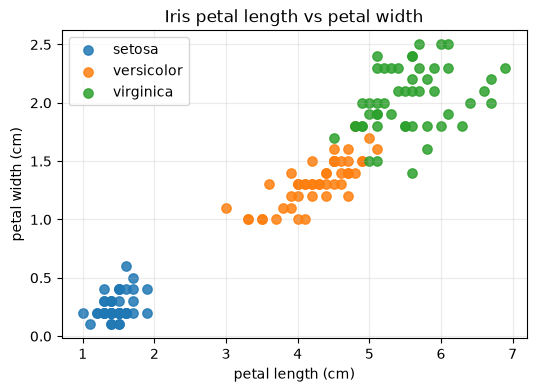

In [ ]:
plt.figure(figsize=(6, 4))
for label_id, class_name in enumerate(iris.target_names):
    mask = y_iris == label_id
    plt.scatter(
        X_iris.loc[mask, "petal length (cm)"],
        X_iris.loc[mask, "petal width (cm)"],
        label=class_name,
        s=45,
        alpha=0.85,
    )
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.title("Iris petal length vs petal width")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

### 常见方法

scikit-learn 的对象命名比较统一。先对这些方法有个印象，后面的代码会反复用到。

| 对象 | 例子 | 常见方法 | 含义 |
| --- | --- | --- | --- |
| 模型 | 线性回归、逻辑回归、KMeans | `fit` | 根据数据学习参数 |
| 训练结束的模型 | 回归模型、分类模型 | `predict` | 预测新样本 |
| 预处理器 | 标准化、独热编码 | `transform` | 转换数据 |
| Pipeline | 预处理 + 模型 | `fit` / `predict` | 按顺序执行多个步骤 |
| 评估函数 | accuracy、MSE | 函数调用 | 比较预测值和真实值 |

典型写法：

```python
model = SomeModel(...)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
```

这只是调用形式。训练集、测试集、逻辑回归和 accuracy 会在后面分别说明。


## Part 1：数据加载、划分和预处理

### Overview

模型训练前的准备工作很重要：数据怎样划分、怎样标准化、预处理是否泄漏测试集信息，都会影响结果是否可信。

### 标准化 StandardScaler

很多模型对特征尺度比较敏感。比如一列是年龄，范围大约是 0 到 100；另一列是收入，范围可能是几千到几万。数值范围差很多时，模型可能更容易被“大数值”的列影响。

`StandardScaler` 对每一列分别做：

$$
z=\frac{x-\mu}{\sigma}
$$

其中 $\mu$ 是这一列在训练集上的均值，$\sigma$ 是这一列在训练集上的标准差。这称作 z-score 标准化。

所以：

- `fit`：计算每一列的 $\mu$ 和 $\sigma$。
- `transform`：用已经算好的 $\mu$ 和 $\sigma$ 转换数据。
- `fit_transform`：先 `fit`，再立刻 `transform`。

下面用 Iris 的前几行数据看标准化前后的数值变化。


In [411]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_small = X_iris.iloc[:5, :2]
print("原始数据:")
print(X_small)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_small) # 一种shortcut，等价于 scaler.fit(X_small); X_scaled = scaler.transform(X_small)
print("标准化后:")
print(np.round(X_scaled, 2))


原始数据:
   sepal length (cm)  sepal width (cm)
0                5.1               3.5
1                4.9               3.0
2                4.7               3.2
3                4.6               3.1
4                5.0               3.6
标准化后:
[[ 1.29  0.95]
 [ 0.22 -1.21]
 [-0.86 -0.35]
 [-1.4  -0.78]
 [ 0.75  1.38]]


### Pipeline

很多模型不能直接输入原始数据，需要先做预处理。比如逻辑回归常常会先标准化：

```text
原始 X -> StandardScaler -> 标准化后的 X -> LogisticRegression -> 预测结果
```

`Pipeline` 就是把这几步打包成一个对象。打包之后，它看起来也像一个普通模型：可以 `fit`，也可以 `predict` 或 `score`。

以 `StandardScaler + LogisticRegression` 为例：

```python
pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(),
)
```

调用：

```python
pipe.fit(X_train, y_train)
```

内部大致做了这些事：

1. `StandardScaler.fit(X_train)`：只用训练集计算均值和标准差。
2. `StandardScaler.transform(X_train)`：把训练集标准化。
3. `LogisticRegression.fit(X_train_scaled, y_train)`：用标准化后的训练集训练模型。

之后调用：

```python
pipe.score(X_test, y_test)
```

Pipeline 会自动用训练集里学到的均值和标准差去处理 `X_test`，再交给逻辑回归预测。

这样写的好处是：预处理和模型不会散在几段代码里，也不容易把测试集拿去 `fit`。


In [412]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# 随机切分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X_iris,
    y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris,
)

pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)

# fit 会依次执行：标准化器 fit/transform -> 逻辑回归 fit
pipe.fit(X_train, y_train)

# score 会依次执行：用同一个标准化器 transform 测试集 -> 逻辑回归预测 -> 计算默认分数
print("pipeline score:", pipe.score(X_test, y_test))
pipe # Jupyter的富展示机制


pipeline score: 0.9333333333333333


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 类别特征 OneHotEncoder

真实表格数据常有字符串类别，例如城市、性别、专业。许多模型不能直接处理字符串，需要先把类别变成数字特征。

One-hot 编码的思想是：一个类别值对应一个 0/1 位置。比如城市有三种取值：

```text
Beijing, Shanghai, Shenzhen
```

那么 `Beijing` 可以表示成 `[1, 0, 0]`，`Shanghai` 可以表示成 `[0, 1, 0]`。

`OneHotEncoder` 的 `fit` 会先看训练数据里有哪些类别；`transform` 再按照这些类别生成 0/1 特征。


In [413]:
cities = pd.DataFrame({"city": ["Beijing", "Shanghai", "Beijing", "Shenzhen"]})
encoder = OneHotEncoder(sparse_output=False)
encoded = encoder.fit_transform(cities)

print(encoder.get_feature_names_out())
print(encoded)
print(encoder.inverse_transform(encoded))
encoder


['city_Beijing' 'city_Shanghai' 'city_Shenzhen']
[[1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]]
[['Beijing']
 ['Shanghai']
 ['Beijing']
 ['Shenzhen']]


,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequen

## 真实表格数据的预处理

真实表格数据通常不会像 Iris 那样干净。常见问题有两类：

- 有些位置缺失，例如年龄未知、城市为空。
- 不同列类型不同，例如 `age` 是数字，`city` 是类别。

scikit-learn 里常用这几个对象处理表格数据：

| 对象 | 用来做什么 |
| --- | --- |
| `SimpleImputer` | 填补缺失值，例如用中位数或最常见类别补空值 |
| `StandardScaler` | 标准化数值列 |
| `OneHotEncoder` | 把类别列变成 0/1 编码 |
| `ColumnTransformer` | 指定哪些列走数值流程，哪些列走类别流程 |
| `Pipeline` | 把预处理和模型按顺序串起来 |

下面构造一张小型表格，模拟真实任务里常见的混合特征。

处理规则：

- 数值列：先用中位数填补缺失值，再标准化。
- 类别列：先用出现最多的类别填补缺失值，再做 one-hot 编码。
- 最后把两部分处理后的特征拼回一张表，交给分类模型。

`ColumnTransformer` 的作用就是管理“不同列走不同处理流程”这件事。


In [414]:
raw_people = pd.DataFrame({
    "age": [18, 21, np.nan, 35, 46, 52, 23, np.nan],
    "income": [3.2, 4.5, 3.8, np.nan, 8.0, 7.5, 4.1, 6.2],
    "city": ["Beijing", "Shanghai", "Beijing", "Shenzhen", "Shanghai", None, "Beijing", "Shenzhen"],
    "major": ["CS", "Math", "CS", "Physics", "Math", "CS", None, "Physics"],
    "accepted": [0, 0, 0, 1, 1, 1, 0, 1],
})
raw_people

,age,income,city,major,accepted
0,18.0,3.2,Beijing,CS,0
1,21.0,4.5,Shanghai,Math,0
2,NaN,3.8,Beijing,CS,0
3,35.0,NaN,Shenzhen,Physics,1
4,46.0,8.0,Shanghai,Math,1
5,52.0,7.5,NaN,CS,1
6,23.0,4.1,Beijing,NaN,0
7,NaN,6.2,Shenzhen,Physics,1


In [415]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 数值列和类别列要分开处理。
numeric_features = ["age", "income"]
categorical_features = ["city", "major"]

# 数值列流程：
# 1. SimpleImputer(strategy="median")：用每一列的中位数填补 NaN。
# 2. StandardScaler()：把数值列标准化。
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# 类别列流程：
# 1. SimpleImputer(strategy="most_frequent")：用每一列出现最多的类别填补缺失值。
# 2. OneHotEncoder：把字符串类别变成 0/1 特征。
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# ColumnTransformer 指定：哪些列用 numeric_transformer，哪些列用 categorical_transformer。
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

X_people = raw_people.drop(columns="accepted")
y_people = raw_people["accepted"]

# fit_transform 会分别 fit 两条分支，然后把处理后的列拼接起来。
X_people_processed = preprocessor.fit_transform(X_people)
print(X_people_processed.shape)
print(np.round(X_people_processed, 2))


(8, 8)
[[-1.21 -1.21  1.    0.    0.    1.    0.    0.  ]
 [-0.94 -0.43  0.    1.    0.    0.    1.    0.  ]
 [-0.23 -0.85  1.    0.    0.    1.    0.    0.  ]
 [ 0.3  -0.43  0.    0.    1.    0.    0.    1.  ]
 [ 1.27  1.66  0.    1.    0.    0.    1.    0.  ]
 [ 1.8   1.36  1.    0.    0.    1.    0.    0.  ]
 [-0.76 -0.67  1.    0.    0.    1.    0.    0.  ]
 [-0.23  0.58  0.    0.    1.    0.    0.    1.  ]]


In [416]:
# 最外层 Pipeline：先做整套表格预处理，再训练分类器。
tabular_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(solver="liblinear")),
])

tabular_model.fit(X_people, y_people)
print("training score:", tabular_model.score(X_people, y_people))
tabular_model


training score: 1.0


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['age','income','city','major']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specif

## Part 2：监督学习一：回归

### 什么是监督学习

监督学习处理的是“带答案的数据”。训练时，每个样本都有一组特征 `X`，也有对应的答案 `y`。

```text
训练数据： (X, y)
新样本：   X_new
模型输出： y_pred
```

监督学习常见两类任务：

| 任务 | `y` 的样子 | 例子 |
| --- | --- | --- |
| 回归 regression | 连续数值 | 预测房价、温度、疾病指标 |
| 分类 classification | 离散类别 | 判断邮件是否垃圾、肿瘤良性/恶性 |

本节先讲回归。回归任务里，模型输出的是一个数值。


### 什么是线性回归

把一个样本的所有特征写成向量：

$$
\mathbf{x}=\begin{bmatrix}x_1 & x_2 & \cdots & x_d\end{bmatrix}^\top
$$

模型也有一个同样长度的权重向量：

$$
\mathbf{w}=\begin{bmatrix}w_1 & w_2 & \cdots & w_d\end{bmatrix}^\top
$$

线性回归的预测值写成内积形式：

$$
\hat{y}=\mathbf{w}^T\mathbf{x}+b
$$

这里 $\mathbf{w}$ 是权重向量，$b$ 是偏置项，$\hat{y}$ 是模型预测值。

训练时，模型会调整 $\mathbf{w}$ 和 $b$，让预测值和真实值尽量接近。常见目标是让均方误差 MSE 尽量小：

$$
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

这个式子里，$n$ 是样本数量，$y_i$ 是第 $i$ 个样本的真实值，$\hat{y}_i$ 是模型预测值。


### 例：糖尿病数据集

下面换成 sklearn 内置的 diabetes 数据集。

这个数据集里：

- 一行表示一位病人的检查记录。
- `X_reg` 是病人的 10 个数值特征，例如年龄、性别、BMI、血液指标等经过处理后的数值。
- `y_reg` 是一年后疾病进展程度的量化指标，是连续数值。

因为 `y_reg` 是连续数值，所以这是回归任务。模型要从病人的特征 `X_reg` 预测疾病进展指标 `y_reg`。

先看数据形状和前几行，再训练 `LinearRegression`。


In [24]:
from sklearn.datasets import load_diabetes

# diabetes 是回归数据集：每一行是一位病人，y 是连续的疾病进展指标。
diabetes = load_diabetes(as_frame=True)
X_reg = diabetes.data      # 特征表：病人的 10 个数值特征
y_reg = diabetes.target    # 目标值：一年后疾病进展程度

print("X shape:", X_reg.shape)
print("y shape:", y_reg.shape)
X_reg.head()


X shape: (442, 10)
y shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [25]:
y_reg.describe()


count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

### 训练模型与评价指标

接下来用 `LinearRegression` 训练模型，并在测试集上评价。

回归任务常见的评价指标有：

$$
\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

MAE 是平均绝对误差，单位和原来的 `y` 一样，比较容易解释。

$$
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

MSE 会把较大的错误放大，所以对离谱预测更敏感。

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

$R^2$ 可以理解为：模型相比“永远预测平均值 $\bar{y}$”这个基准方法，好了多少。

- $R^2=1$：预测完全正确。
- $R^2=0$：和永远预测平均值差不多。
- $R^2<0$：还不如永远预测平均值。



In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 先切分，再训练。测试集只用于最后评估。
X_train, X_test, y_train, y_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42,
)

reg = LinearRegression()
reg.fit(X_train, y_train)
y_pred_reg = reg.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_reg))
print("MSE:", mean_squared_error(y_test, y_pred_reg))
print("R2:", r2_score(y_test, y_pred_reg))


NameError: name 'train_test_split' is not defined

### 拟合趋势

上面的 `reg` 已经用全部 10 个特征训练好了。为了把结果画在二维图里，下面固定其他 9 个特征为训练集均值，只改变 `bmi`，观察模型预测值怎样变化。

散点是真实样本，红线是训练后的线性回归模型给出的预测趋势。


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 固定其他特征为训练集均值，只让 bmi 在原始范围内变化。
bmi_grid = np.linspace(X_reg["bmi"].min(), X_reg["bmi"].max(), 100)
X_curve = pd.DataFrame(
    np.repeat(X_train.mean().to_numpy()[None, :], len(bmi_grid), axis=0),
    columns=X_train.columns,
)
X_curve["bmi"] = bmi_grid
y_curve = reg.predict(X_curve)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_reg["bmi"], y_reg, alpha=0.45, s=28, label="samples")
plt.plot(bmi_grid, y_curve, color="crimson", linewidth=2.5, label="fitted trend")
plt.xlabel("bmi feature")
plt.ylabel("disease progression target")
plt.title("Fitted trend from the trained linear regression model")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


NameError: name 'X_reg' is not defined

In [ ]:
pd.DataFrame({
    "y_true": y_test.to_numpy()[:10],
    "y_pred": np.round(y_pred_reg[:10], 1),
})

NameError: name 'y_test' is not defined

### OJ 1：糖尿病指标预测

[糖尿病指标预测](https://oj.cs.tsinghua.edu.cn/course/94/contest/1055/problem/1)

## Part 3：监督学习二：分类与逻辑回归

### Overview

分类也是监督学习。和回归不同，分类任务的 `y` 不是连续数值，而是类别。

逻辑回归是一个常用的线性分类模型。本节先看它的数学形式，再用乳腺癌数据集做一个二分类例子。


### 什么是逻辑回归

逻辑回归名字里有“回归”，但它常用于分类。

和线性回归一样，先把样本写成特征向量 $\mathbf{x}$，再计算一个线性分数：

$$
z=\mathbf{w}^T\mathbf{x}+b
$$

然后用激活函数把分数 $z$ 变成 0 到 1 之间的概率。对于二分类，常用的激活函数是 sigmoid 函数：

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

二分类时，可以把 $\sigma(z)$ 理解成属于正类的概率：

$$
P(y=1\mid \mathbf{x})=\sigma(\mathbf{w}^T\mathbf{x}+b)
$$

常见分类规则是：

```text
p >= 0.5 -> 预测为 1
p <  0.5 -> 预测为 0
```

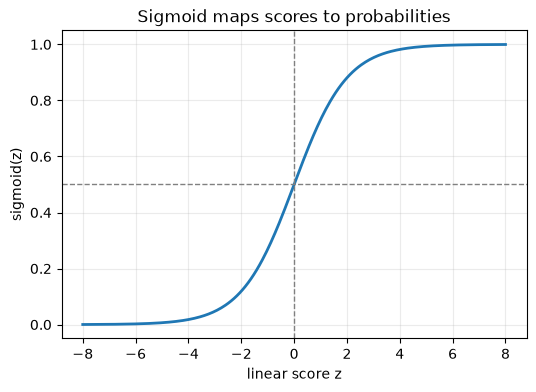

In [422]:
z = np.linspace(-8, 8, 300)
p = 1 / (1 + np.exp(-z))

plt.figure(figsize=(6, 4))
plt.plot(z, p, linewidth=2)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.xlabel("linear score z")
plt.ylabel("sigmoid(z)")
plt.title("Sigmoid maps scores to probabilities")
plt.grid(True, alpha=0.25)
plt.show()


### 例：乳腺癌数据集

下面使用 sklearn 内置的 Wisconsin breast cancer 数据集。

这个数据集里：

- 一行表示一个肿瘤样本。
- `X_cls` 是肿瘤的 30 个测量特征。
- `y_cls` 是类别标签，表示 malignant / benign。

模型要根据测量特征判断肿瘤类别。


In [423]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, confusion_matrix

# breast cancer 是二分类数据集：每一行是一个肿瘤样本。
cancer = load_breast_cancer()
X_cls = cancer.data      # 特征表：肿瘤的 30 个测量特征
y_cls = cancer.target    # 标签：0/1 类别，对应 malignant / benign

print("X shape:", X_cls.shape)
print("y shape:", y_cls.shape)
print("target names:", cancer.target_names)
print("前 8 个特征名:", cancer.feature_names[:8])

X shape: (569, 30)
y shape: (569,)
target names: ['malignant' 'benign']
前 8 个特征名: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points']


In [424]:
counts = pd.Series(y_cls).value_counts().sort_index()
pd.DataFrame({
    "label_id": counts.index,
    "target_name": cancer.target_names[counts.index],
    "count": counts.values,
})

,label_id,target_name,count
0,0,malignant,212
1,1,benign,357


In [425]:
# 先划分训练集和测试集，再把标准化和逻辑回归放进同一个 Pipeline。
X_train, X_test, y_train, y_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    random_state=42,
    stratify=y_cls,
)

cls_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="liblinear"),
)
cls_pipe.fit(X_train, y_train)

pd.DataFrame({
    "split": ["train", "test"],
    "n_samples": [X_train.shape[0], X_test.shape[0]],
    "n_features": [X_train.shape[1], X_test.shape[1]],
})


,split,n_samples,n_features
0,train,426,30
1,test,143,30


### 分类指标的数学直觉

对于分类任务，我们不只看 accuracy，混淆矩阵和 `classification_report` 能告诉我们错在哪里。

二分类里常用四个计数：

| 记号 | 含义 |
| --- | --- |
| TP | 真实为正，预测也为正 |
| FP | 真实为负，预测为正 |
| FN | 真实为正，预测为负 |
| TN | 真实为负，预测也为负 |

常见指标：

$$
\mathrm{accuracy}=\frac{TP+TN}{TP+FP+FN+TN}
$$

$$
\mathrm{precision}=\frac{TP}{TP+FP}
$$

$$
\mathrm{recall}=\frac{TP}{TP+FN}
$$

$$
F1=\frac{2\cdot precision\cdot recall}{precision+recall}
$$

accuracy 回答“总体对了多少”；precision 更关心“预测为正的里面有多少是真的”；recall 更关心“真实为正的里面找回了多少”。

什么时候更看重 precision，什么时候更看重 recall，取决于哪种错误代价更高。

| 更关心 | 适合场景 | 主要想减少 |
| --- | --- | --- |
| precision | 垃圾邮件拦截、自动封号 | 误伤正常样本，即 FP |
| recall | 疾病初筛、风险预警 | 漏掉真正阳性，即 FN |

通常提高 recall 会让模型更“积极”地报阳性，可能牺牲 precision；提高 precision 会让模型更谨慎，可能漏掉更多阳性。F1 是二者的折中。


In [426]:
cls_pred = cls_pipe.predict(X_test) # 预测的类别
cls_proba = cls_pipe.predict_proba(X_test) # 预测的概率

pd.DataFrame({
    "true": y_test[:10],
    "pred": cls_pred[:10],
    "prob_class_0": np.round(cls_proba[:10, 0], 3),
    "prob_class_1": np.round(cls_proba[:10, 1], 3),
})

,true,pred,prob_class_0,prob_class_1
0,1,1,0.032,0.968
1,0,0,1.000,0.000
2,1,1,0.444,0.556
3,1,1,0.062,0.938
4,0,0,0.827,0.173
5,0,0,1.000,0.000
6,0,0,0.997,0.003
7,0,0,0.999,0.001
8,0,0,0.999,0.001
9,1,1,0.000,1.000


In [427]:
acc = accuracy_score(y_test, cls_pred)
print(f"accuracy = {acc:.4f}")


accuracy = 0.9860


In [428]:
from sklearn.metrics import classification_report

# confusion_matrix 的行是真实类别，列是预测类别。
# 对二分类且标签顺序为 [0, 1] 时，矩阵含义是：
# [[TN, FP],
#  [FN, TP]]
print(confusion_matrix(y_test, cls_pred))
print(classification_report(y_test, cls_pred, target_names=cancer.target_names))


[[52  1]
 [ 1 89]]
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



### 和基准方法比较

模型分数要有参照物。一个很弱但有用的基准是：永远预测训练集中最多的类别。

`DummyClassifier(strategy="most_frequent")` 就是在做这件事。如果一个模型连这个基准都比不过，通常说明它没有学到有用规律。



In [429]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("dummy accuracy:", accuracy_score(y_test, dummy_pred))
print("dummy macro F1:", f1_score(y_test, dummy_pred, average="macro"))
print(confusion_matrix(y_test, dummy_pred))
print(classification_report(y_test, dummy_pred, target_names=cancer.target_names, zero_division=0))


dummy accuracy: 0.6293706293706294
dummy macro F1: 0.38626609442060084
[[ 0 53]
 [ 0 90]]
              precision    recall  f1-score   support

   malignant       0.00      0.00      0.00        53
      benign       0.63      1.00      0.77        90

    accuracy                           0.63       143
   macro avg       0.31      0.50      0.39       143
weighted avg       0.40      0.63      0.49       143



### 多分类

前面的乳腺癌数据集是二分类：每个样本只会属于两个类别之一。多分类任务里，`y` 可以有三个或更多类别，比如 Iris 数据集有 3 类鸢尾花。

可以把二分类看成多分类的一种特殊情况：二分类是 2 个类别，多分类是 $K$ 个类别。模型最后都要回答同一个问题：这个样本属于每个类别的概率分别是多少？

下面用 Iris 数据集看一下 `predict_proba` 的输出：

- 每一行对应一个样本。
- 每一列对应一个类别。
- 同一行的概率加起来约等于 1。



In [430]:
from sklearn.datasets import load_iris

iris_multi = load_iris(as_frame=True)
X_multi = iris_multi.data
y_multi = iris_multi.target

X_multi_train, X_multi_test, y_multi_train, y_multi_test = train_test_split(
    X_multi,
    y_multi,
    test_size=0.25,
    random_state=42,
    stratify=y_multi,
)

multi_clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=200),
)
multi_clf.fit(X_multi_train, y_multi_train)

multi_pred = multi_clf.predict(X_multi_test)
multi_proba = multi_clf.predict_proba(X_multi_test)

print("classes:", multi_clf.classes_)
print("accuracy:", accuracy_score(y_multi_test, multi_pred))

pd.DataFrame(
    np.round(multi_proba[:5], 3),
    columns=iris_multi.target_names,
)


classes: [0 1 2]
accuracy: 0.9210526315789473


,setosa,versicolor,virginica
0,0.985,0.015,0.000
1,0.034,0.621,0.345
2,0.045,0.882,0.072
3,0.011,0.916,0.073
4,0.968,0.032,0.000


### softmax 与训练目标

上一小节看到，多分类模型会为每个样本输出一组类别概率。逻辑回归里，这组概率通常来自 softmax。

假设一共有 $K$ 个类别，输入特征有 $d$ 维。多分类逻辑回归会为每个类别各学一组权重和一个偏置。整体来看，权重是一个矩阵，偏置是一个向量：

$$
W=\begin{bmatrix}\mathbf{w}_1 & \mathbf{w}_2 & \cdots & \mathbf{w}_K\end{bmatrix}\in\mathbb{R}^{d\times K},\quad \mathbf{b}\in\mathbb{R}^{K}
$$

对一个样本 $\mathbf{x}_i$，第 $k$ 类的线性分数是：

$$
z_{ik}=\mathbf{w}_k^T\mathbf{x}_i+b_k,\quad k=1,2,\ldots,K
$$

把所有类别的分数放在一起，可以写成一个向量：

$$
\mathbf{z}_i=W^T\mathbf{x}_i+\mathbf{b}
$$

这些分数本身还不是概率。softmax 把它们转换成每个类别的概率：

$$
p_{ik}=P(y_i=k\mid \mathbf{x}_i)=\frac{e^{z_{ik}}}{\sum_{j=1}^{K}e^{z_{ij}}}
$$

softmax 的输出满足两个性质：

- 每个 $p_{ik}$ 都在 0 到 1 之间。
- 同一个样本的所有类别概率加起来等于 1。

训练时，模型希望真实类别的概率尽量大。如果第 $i$ 个样本的真实类别是 $y_i$，那么我们希望 $P(y_i\mid \mathbf{x}_i)$ 越大越好。对所有样本，可以写成最大化：

$$
\prod_{i=1}^{n}P(y_i\mid \mathbf{x}_i)
$$

直接处理乘积不方便，所以通常取负对数，把问题改写成最小化交叉熵损失：

$$
\mathcal{L}=-\frac{1}{n}\sum_{i=1}^{n}\log P(y_i\mid \mathbf{x}_i)
$$

如果把真实标签写成 one-hot 形式 $y_{ik}$，也可以写成：

$$
\mathcal{L}=-\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{K}y_{ik}\log p_{ik}
$$

这个式子只会取出真实类别对应的那一项。真实类别概率越低，损失越大。


二分类时，softmax 会退化成 sigmoid。假设两类分数是 $z_0$ 和 $z_1$，softmax 给第 1 类的概率是：

$$
P(y=1\mid\mathbf{x})=\frac{e^{z_1}}{e^{z_0}+e^{z_1}}
$$

上下同时除以 $e^{z_1}$：

$$
P(y=1\mid\mathbf{x})=\frac{1}{1+e^{z_0-z_1}}=\frac{1}{1+e^{-(z_1-z_0)}}
$$

这就是 sigmoid 的形式。也就是说，二分类逻辑回归可以看成多分类 softmax 在 $K=2$ 时的简化写法。


那么这个最小值怎么求？逻辑回归通常没有像普通最小二乘线性回归那样简单的闭式解，所以 `fit` 会使用数值优化方法来找参数。

以梯度下降的想法为例，先从一组初始参数出发，计算损失函数对参数的梯度，再沿着让损失下降的方向更新参数。多分类时更新的是权重矩阵和偏置向量：

$$
W \leftarrow W - \eta \nabla_W\mathcal{L}
$$

$$
\mathbf{b} \leftarrow \mathbf{b} - \eta \nabla_{\mathbf{b}}\mathcal{L}
$$

其中 $\eta$ 是学习率，$\nabla_W\mathcal{L}$ 和 $\nabla_{\mathbf{b}}\mathcal{L}$ 分别表示损失函数对权重矩阵和偏置向量的梯度。

scikit-learn 里的 `solver` 参数控制具体使用哪种优化算法，例如 `lbfgs`、`liblinear`、`saga` 等。它们不一定是最朴素的梯度下降，但目标是一致的：找到一组让损失函数更小的权重和偏置。



### 正则化参数 `C`

逻辑回归默认会带正则化。正则化的作用是限制权重不要过大，减少过拟合风险。

如果把前面讲的交叉熵损失记为 $\mathcal{L}$，加入 L2 正则化后，目标可以理解成：

$$
\mathcal{L}+\lambda\sum_{k=1}^{K}\|\mathbf{w}_k\|_2^2
$$

前一项要求预测概率贴近真实标签，后一项限制权重不要过大。

在 `LogisticRegression` 里，参数名不是 $\lambda$，而是 `C`。直观上可以把它理解成和正则化系数成反比：

$$
\lambda \approx \frac{1}{C}
$$

所以：

```text
C 越小 -> lambda 越大 -> 正则化越强，模型更保守
C 越大 -> lambda 越小 -> 正则化越弱，模型更愿意贴合训练数据
```

后面的 `GridSearchCV` 会尝试多个 `C`，用交叉验证选择效果较好的值。


### OJ 2：乳腺癌分类预测

[乳腺癌分类预测](https://oj.cs.tsinghua.edu.cn/course/94/contest/1055/problem/4)

## Part 4：非监督学习：KMeans 聚类

### Overview

监督学习有标签，非监督学习没有标签。聚类会根据样本相似程度自动分组。

KMeans 的基本过程：选中心、分配样本、更新中心、重复直到稳定。

### 什么是 KMeans

KMeans 是非监督学习算法。它训练时只有输入数据 $X$，没有标签 $y$。

它要做的是：把样本分成 $k$ 组，同时为每一组找到一个中心点。KMeans 的目标不是“随便找几个中心”，而是让每个点到自己所属中心的距离尽量小。常见目标函数是组内平方距离和：

$$
\sum_{i=1}^{n}\left\|\mathbf{x}_i-\mathbf{c}_{label_i}\right\|_2^2
$$

其中 $\mathbf{x}_i$ 是第 `i` 个样本向量，$\mathbf{c}_{label_i}$ 是它所属簇的中心向量。

KMeans 的 `fit(X)` 会交替做两件事：

1. **固定中心，分配样本**：对每个样本 $\mathbf{x}_i$，找到离它最近的中心，把它分到那个簇。  
   在中心已经确定的情况下，分给最近中心会让这个点贡献的距离最小。

2. **固定分组，更新中心**：对每个簇，重新计算这个簇的中心。  
   对平方距离来说，在分组已经确定的情况下，让组内平方距离最小的中心就是这一组样本的均值。

一维情况证明：假设某一簇里的点是 $x_1, x_2, \dots, x_m$，中心是 $c$，要最小化：

$$
J(c)=\sum_{i=1}^{m}(x_i-c)^2
$$

对 $c$ 求导：

$$
\frac{dJ}{dc}=2\sum_{i=1}^{m}(c-x_i)=2\left(mc-\sum_{i=1}^{m}x_i\right)
$$

令导数为 0，得到：

$$
c=\frac{1}{m}\sum_{i=1}^{m}x_i
$$

也就是均值。多维向量的平方距离可以按每一维分别相加，所以每一维同样取均值，中心就是样本向量的均值。

所以“求平均值”不是随意的操作，而是因为 KMeans 使用的是平方距离目标；固定分组后，均值正好是最优中心。

算法会重复这两步，直到分组和中心基本稳定，或者达到最大迭代次数。这个过程通常会让目标函数下降，但不保证找到全局最优；初始中心会影响结果，所以会有 `random_state` 和 `n_init` 这样的参数。

`fit` 结束后，常用结果有两个：

- `labels_`：每个样本被分到哪个簇。
- `cluster_centers_`：每个簇的中心坐标。

注意：KMeans 不是用人工标签训练出来的。这里的 `label` 是算法自己分出来的组号。



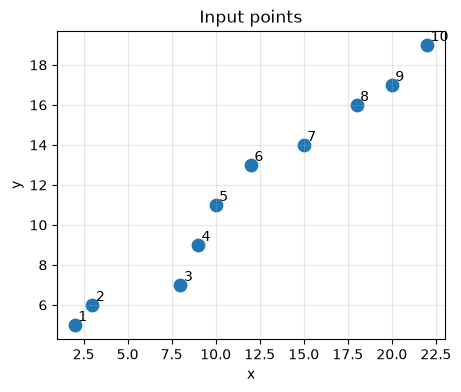

In [431]:
points = np.array([
    [2, 5], [3, 6], [8, 7], [9, 9], [10, 11],
    [12, 13], [15, 14], [18, 16], [20, 17], [22, 19],
], dtype=float)

plt.figure(figsize=(5, 4))
plt.scatter(points[:, 0], points[:, 1], s=80)
for idx, (x, y_point) in enumerate(points, start=1):
    plt.text(x + 0.2, y_point + 0.2, str(idx))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Input points")
plt.grid(True, alpha=0.3)
plt.show()

In [432]:
from sklearn.cluster import KMeans

# n_clusters=3 表示希望分成 3 个簇。
# fit(points) 会迭代寻找簇中心，并给每个样本分配簇编号。
kmeans = KMeans(n_clusters=3, random_state=0, n_init="auto")
kmeans.fit(points)

print("labels:", kmeans.labels_)              # 每个输入点所属的簇编号
print("centers:")
print(kmeans.cluster_centers_)                 # 每个簇的中心坐标


labels: [1 1 1 1 0 0 0 2 2 2]
centers:
[[12.33333333 12.66666667]
 [ 5.5         6.75      ]
 [20.         17.33333333]]


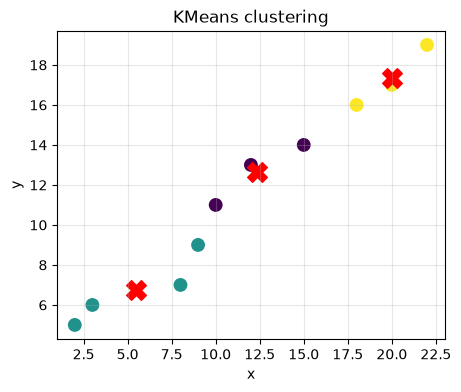

In [433]:
plt.figure(figsize=(5, 4))
plt.scatter(points[:, 0], points[:, 1], c=kmeans.labels_, s=80, cmap="viridis")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="X", s=200, c="red")
plt.xlabel("x")
plt.ylabel("y")
plt.title("KMeans clustering")
plt.grid(True, alpha=0.3)
plt.show()

### OJ 3：尺度不同的聚类

[尺度不同的聚类](https://oj.cs.tsinghua.edu.cn/course/94/contest/1055/problem/2)

## Part 5：模型验证与调参

前面我们多次使用 `train_test_split`。这种做法简单直观，但一次划分可能有偶然性：换一个 `random_state`，训练集和测试集就会变，分数也可能变化。

交叉验证 cross-validation 会把数据分成多份，多次训练、多次验证，再取平均分。它常用于更稳定地估计模型效果。

以 $K$ 折交叉验证为例：把数据分成 $K$ 份，每次拿其中 1 份做验证，其余 $K-1$ 份做训练。最后把 $K$ 次分数取平均：

$$
\mathrm{CVScore}=\frac{1}{K}\sum_{i=1}^{K}score_i
$$

In [434]:
from sklearn.model_selection import cross_val_score

cv_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="liblinear"),
)

scores = cross_val_score(cv_pipe, X_cls, y_cls, cv=5, scoring="accuracy")
print(scores)
print("mean:", scores.mean())


[0.98245614 0.97368421 0.97368421 0.97368421 0.99115044]
mean: 0.9789318428815402


另一个常见问题是调参。模型训练出来的权重叫参数；训练前由我们指定的设置叫超参数。比如 `LogisticRegression` 里的 `C` 就是超参数。

`GridSearchCV` 会对一组候选超参数逐个做交叉验证，再选择平均分最高的组合。

In [435]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100],
}
search = GridSearchCV(cv_pipe, param_grid=param_grid, cv=5, scoring="accuracy")
search.fit(X_cls, y_cls)
search


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed d

### OJ 4：MiniTabularClassifier
[MiniTabularClassifier](https://oj.cs.tsinghua.edu.cn/course/94/contest/1055/problem/3)


## Part 6：总结与扩展

这节课的主线是：

```text
数据表示 -> 划分数据 -> 预处理 -> Pipeline -> 回归/分类 -> 评估 -> 交叉验证/调参 -> 聚类
```

Checklist：

| 场景 | 常用写法 |
| --- | --- |
| 看数据 | `X.head()`, `X.shape`, `y.value_counts()` |
| 划分数据 | `train_test_split(X, y, test_size=..., random_state=...)` |
| 训练模型 | `model.fit(X_train, y_train)` |
| 预处理数据 | `transformer.fit_transform(X_train)`, `transformer.transform(X_test)` |
| 做预测 | `model.predict(X_test)` |
| 评价结果 | `accuracy_score`, `f1_score`, `mean_squared_error`, `r2_score` |
| 串联流程 | `Pipeline`, `make_pipeline` |
| 处理不同列 | `ColumnTransformer` |
| 更稳定地验证 | `cross_val_score` |
| 调超参数 | `GridSearchCV` |
| 非监督聚类 | `KMeans.fit(X)`, `labels_`, `cluster_centers_` |

## 扩展阅读

课后继续学习时，可以先从这些入口开始：

- [scikit-learn Getting Started](https://scikit-learn.org/stable/getting_started.html)：官方入门页。
- [scikit-learn User Guide](https://scikit-learn.org/stable/user_guide.html)：按主题查阅完整说明。
- [scikit-learn Examples](https://scikit-learn.org/stable/auto_examples/index.html)：官方示例库，适合照着运行和修改。
- [Inria scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/)：更系统的 sklearn 在线课程。
- [Kaggle Learn: Intro to Machine Learning](https://www.kaggle.com/learn/intro-to-machine-learning)：偏实践的入门练习。